<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Proportion of unassigned RNA per sample for default, Proseg and Segger segmentation, plus noise summaries.
> - **Manuscript panels:** Fig. 1B
> - **Inputs:** `figures/pipeline_stats.csv` of every `rois*/<dataset>` (output of `2_process_rois*`)
> - **Outputs:** `stacked_barplot_proportions_segmented.pdf`, per-segmentation noise barplots
> - **Environment / kernel:** `troutpy_drvi`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# Aim of the notebook

Visualize the main uRNA quantification (Figure 1 and 2)

# Import modules

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib
import os

#from batch_running import *

/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [2]:
import os
import pandas as pd

# Base directory containing the different segmentation folders
base_dir = "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/"
saving_path = "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/figures/"

# Define the segmentations you want to process
segmentations = ["rois", "rois_proseg","rois_segger"]

# Samples to exclude from all downstream plots
excluded_samples = {"xenium_rcc", "cosmx_pancreas"}

# Explicit column names for the final combined DataFrame
counts_keys = [
    "Intracellular", 
    "Cell-Like Connected",
    "Cell-Like Unconnected", 
    "High-Density Connected",
    "High-Density Unconnected", 
    "Noise Spectrum",
    "Iso. diffusion Compatible", 
    "Iso. diffusion Incompatible"
]

# Dictionary to hold the combined DataFrame for each segmentation
combined_segmentations_dict = {}

for seg in segmentations:
    print(f"\n--- Processing segmentation: {seg} ---")
    
    # Construct the root directory for the current segmentation
    root_dir = os.path.join(base_dir, seg)
    
    if not os.path.exists(root_dir):
        print(f"Directory not found: {root_dir}. Skipping...")
        continue

    # Initialize an empty list to hold individual metadata DataFrames for this segmentation
    metadata_list = []

    # List only first-level subdirectories
    subfolders = [f.path for f in os.scandir(root_dir) if f.is_dir()]

    for subfolder in subfolders:
        sample_name = subfolder.split("/")[-1]
        if sample_name in excluded_samples:
            continue

        metadata_path = os.path.join(subfolder, "figures/transcript_categories.csv")
        
        if os.path.isfile(metadata_path):
            try:
                df = pd.read_csv(metadata_path)
                
                # Use the subfolder name as the temporary column header before transposing
                df.columns = [sample_name]
                
                # Transpose so the subfolder name becomes the row index
                metadata_list.append(df.transpose())
            except Exception as e:
                print(f"Failed to read {metadata_path}: {e}")
                
    # Combine all metadata files into a single DataFrame for this segmentation
    if metadata_list:
        combined_summary = pd.concat(metadata_list, ignore_index=False)
        
        # Apply the explicit column names to the combined DataFrame
        if combined_summary.shape[1] == len(counts_keys):
            combined_summary.columns = counts_keys
        else:
            print(f"Warning: Column count mismatch for '{seg}'. "
                  f"Expected {len(counts_keys)}, got {combined_summary.shape[1]}. "
                  f"Columns were not renamed.")
        
        print(f"Combined metadata shape for '{seg}':", combined_summary.shape)
        
        # Store the resulting DataFrame in the dictionary
        combined_segmentations_dict[seg] = combined_summary
    else:
        print(f"No transcript_categories.csv files found for segmentation '{seg}'.")


--- Processing segmentation: rois ---


Combined metadata shape for 'rois': (17, 8)

--- Processing segmentation: rois_proseg ---


Combined metadata shape for 'rois_proseg': (17, 8)

--- Processing segmentation: rois_segger ---


Combined metadata shape for 'rois_segger': (17, 8)


Generating plot for segmentation: rois


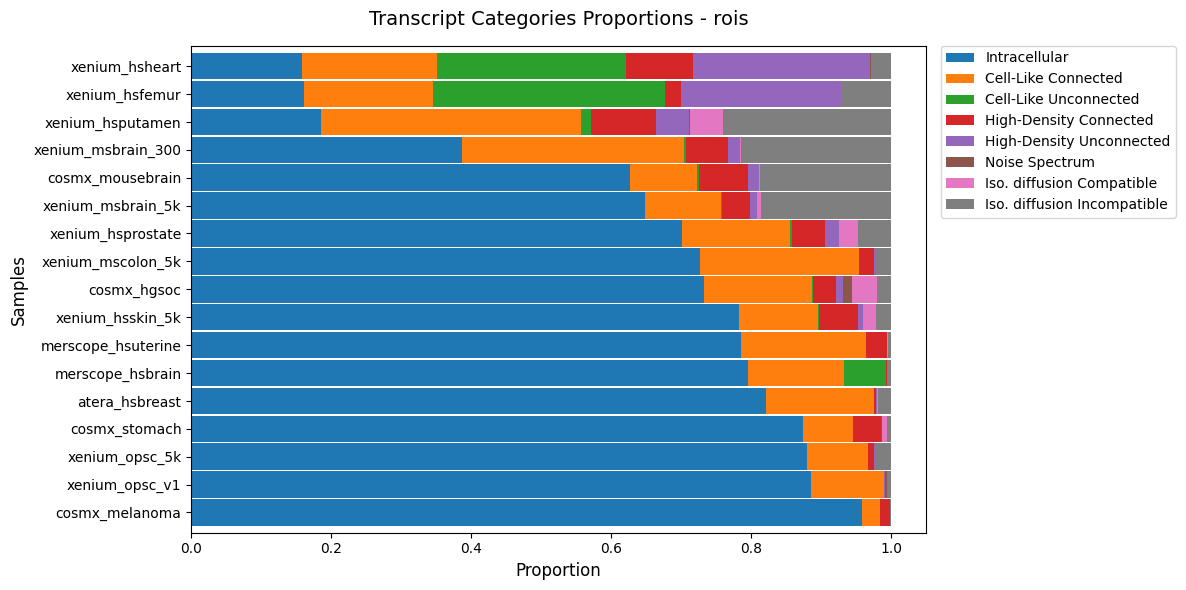

Generating plot for segmentation: rois_proseg


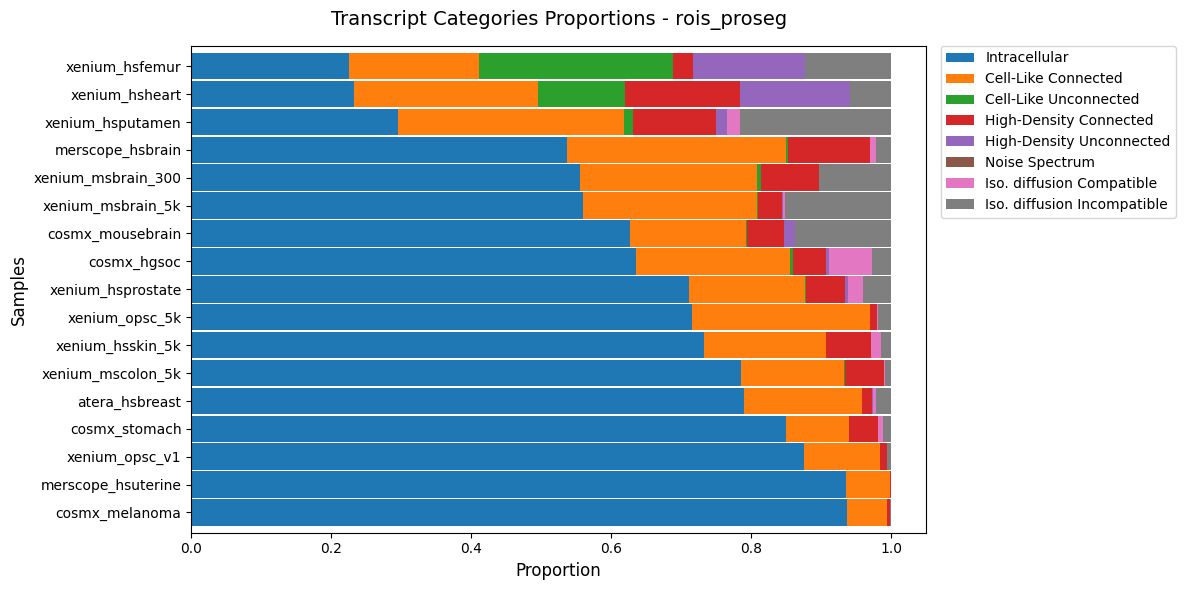

Generating plot for segmentation: rois_segger


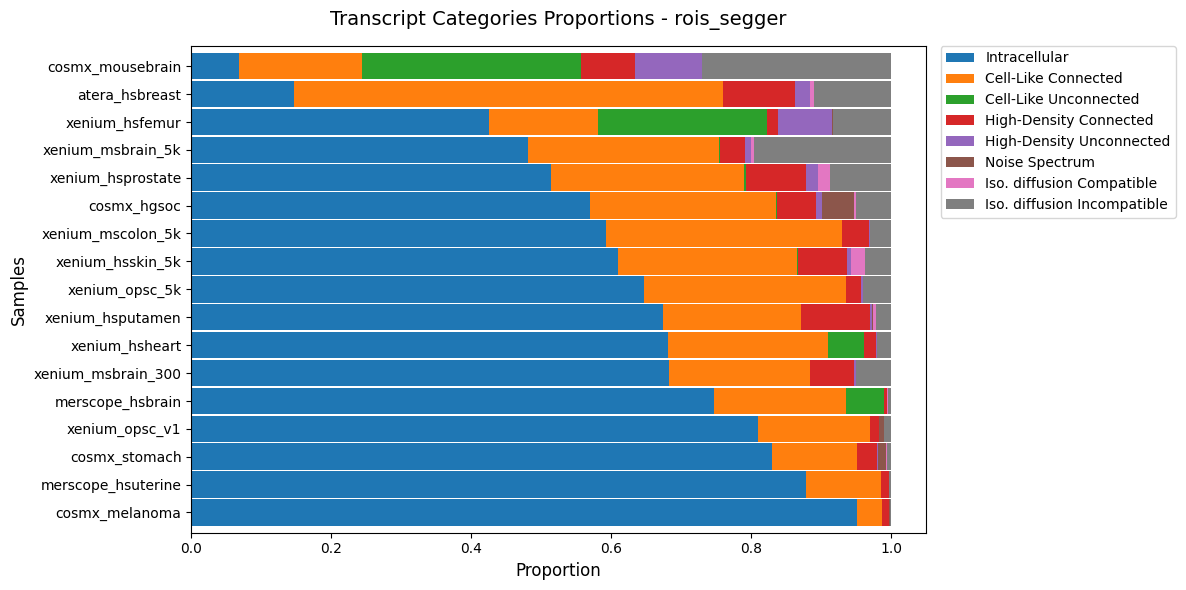

In [3]:
import os
import matplotlib.pyplot as plt

# Ensure the saving directory exists
os.makedirs(saving_path, exist_ok=True)

# Loop through each segmentation stored in the dictionary
for seg, combined_summary in combined_segmentations_dict.items():
    print(f"Generating plot for segmentation: {seg}")

    # 1. Normalize the counts to proportions (rows sum to 1)
    combined_summary_norm = combined_summary.div(
        combined_summary.sum(axis=1), axis=0
    )

    # 2. Setup the figure and axis explicitly
    fig, ax = plt.subplots(figsize=(12, 6))

    # 3. Sort by "Intracellular" and plot
    combined_summary_norm.sort_values(
        by="Intracellular", ascending=False
    ).plot(kind="barh", stacked=True, width=0.95, ax=ax)

    # 4. Clean up formatting and push the legend outside the plot
    plt.title(f"Transcript Categories Proportions - {seg}", fontsize=14, pad=15)
    plt.xlabel("Proportion", fontsize=12)
    plt.ylabel("Samples", fontsize=12)
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
    plt.tight_layout()

    # 5. Save the figure uniquely using the dictionary key
    plot_out_path = os.path.join(saving_path, f"{seg}_summary_plot.png")
    plt.savefig(plot_out_path, dpi=300, bbox_inches="tight")

    # 6. Close the figure to free up memory
    plt.show(fig)

Generating segmentation comparison plot for sample: atera_hsbreast


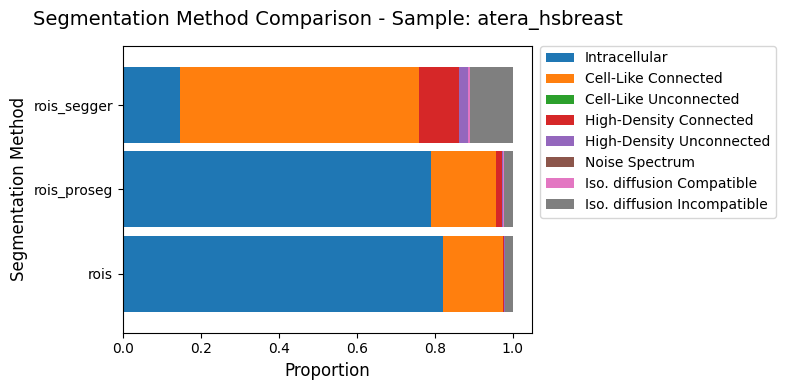

Generating segmentation comparison plot for sample: cosmx_hgsoc


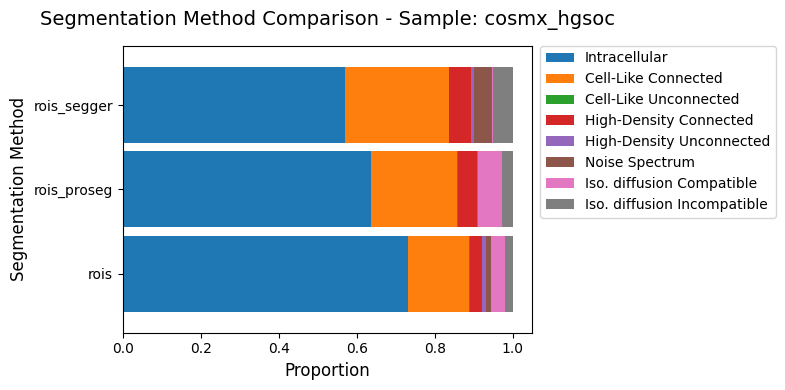

Generating segmentation comparison plot for sample: cosmx_melanoma


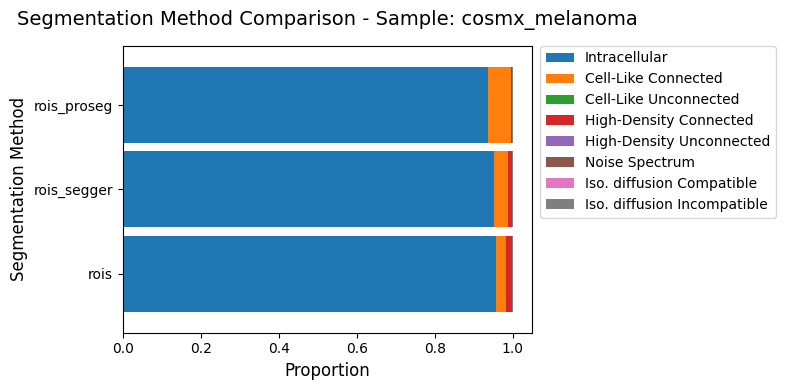

Generating segmentation comparison plot for sample: cosmx_mousebrain


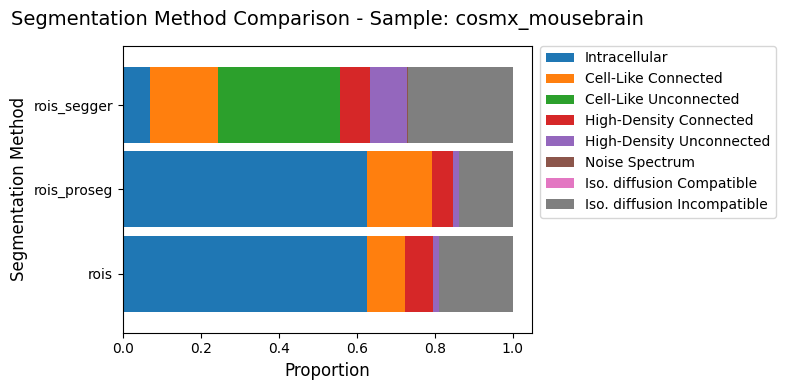

Generating segmentation comparison plot for sample: cosmx_stomach


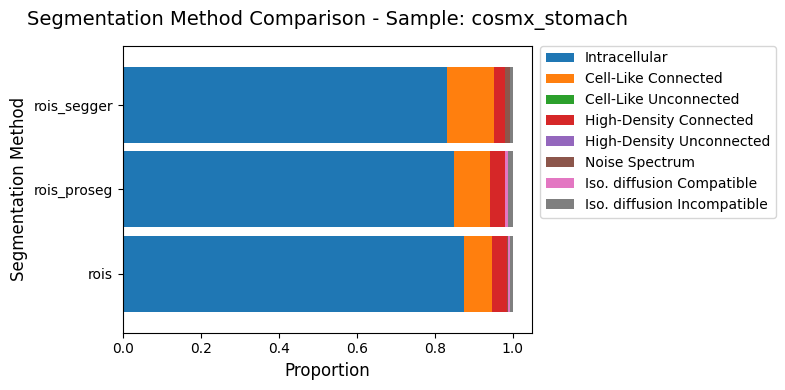

Generating segmentation comparison plot for sample: merscope_hsbrain


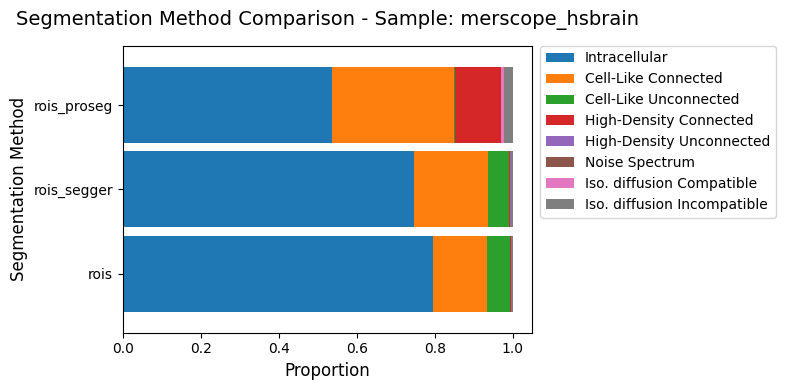

Generating segmentation comparison plot for sample: merscope_hsuterine


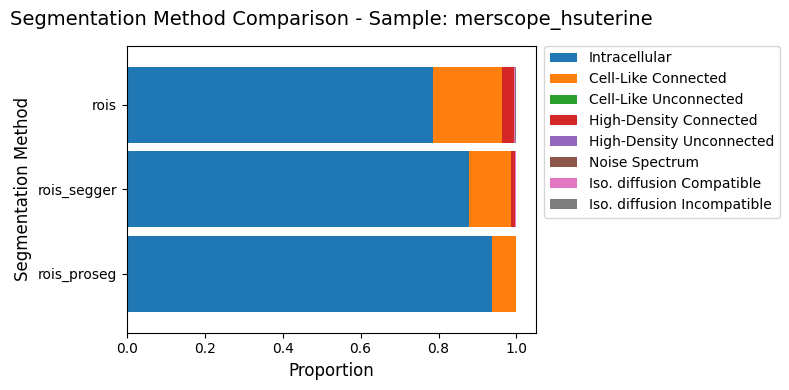

Generating segmentation comparison plot for sample: xenium_hsfemur


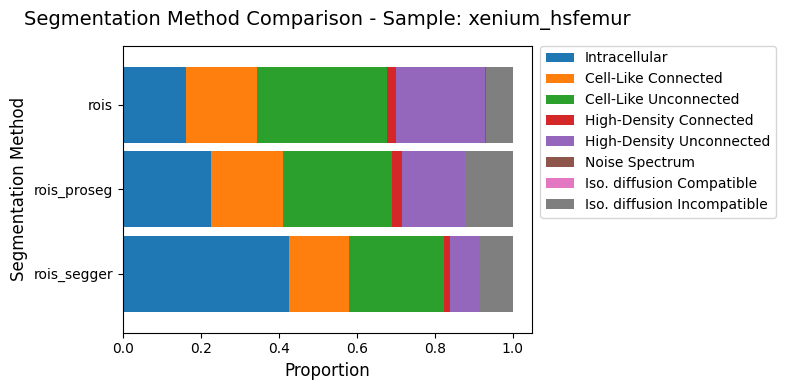

Generating segmentation comparison plot for sample: xenium_hsheart


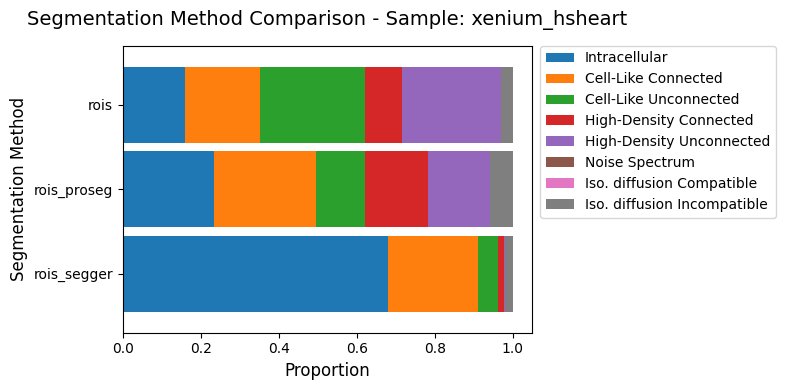

Generating segmentation comparison plot for sample: xenium_hsprostate


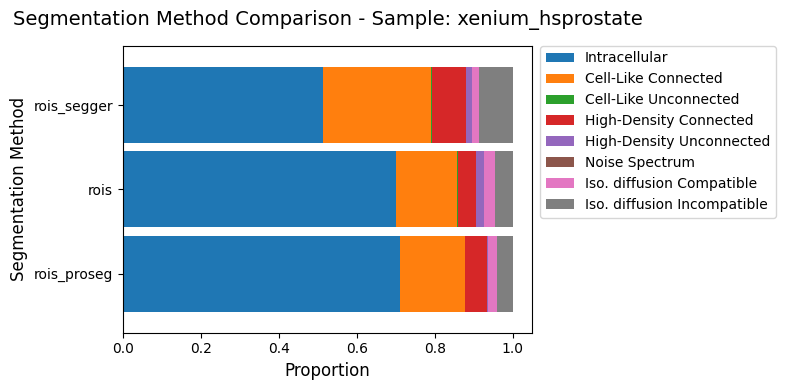

Generating segmentation comparison plot for sample: xenium_hsputamen


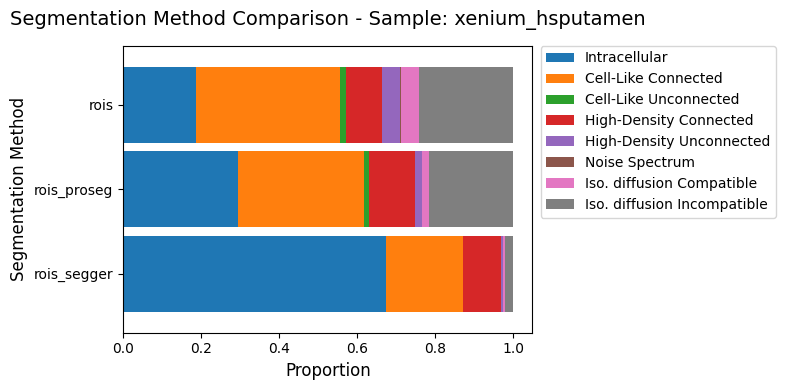

Generating segmentation comparison plot for sample: xenium_hsskin_5k


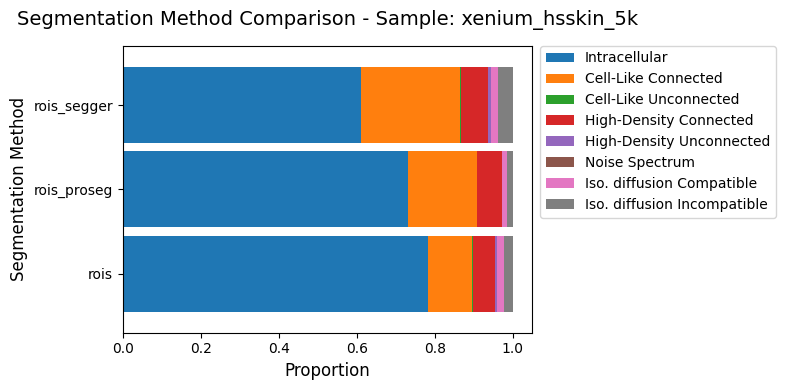

Generating segmentation comparison plot for sample: xenium_msbrain_300


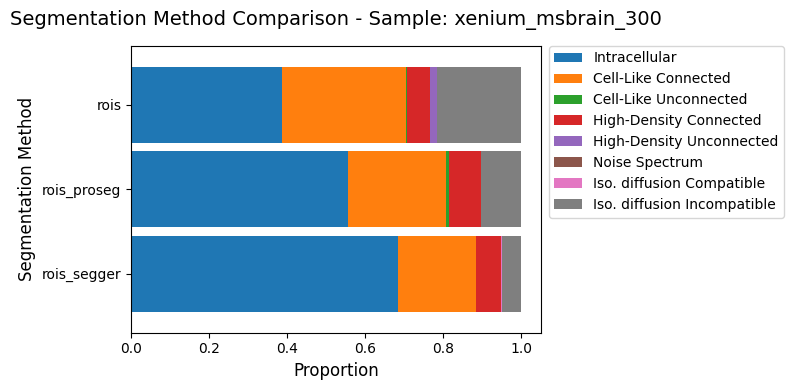

Generating segmentation comparison plot for sample: xenium_msbrain_5k


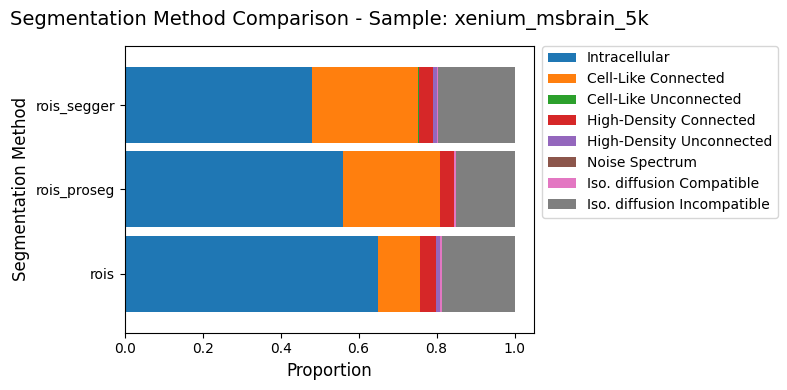

Generating segmentation comparison plot for sample: xenium_mscolon_5k


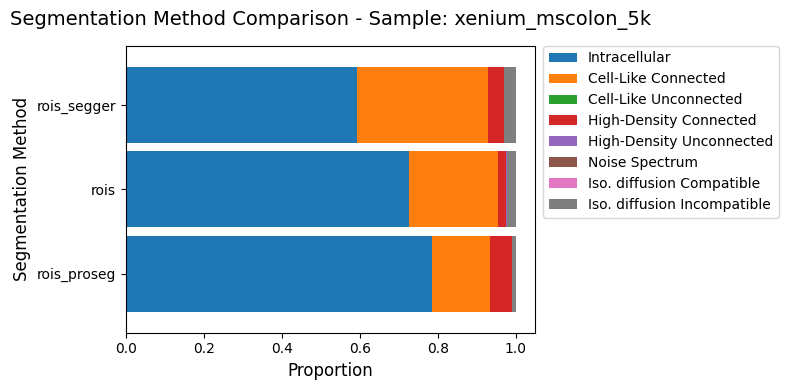

Generating segmentation comparison plot for sample: xenium_opsc_5k


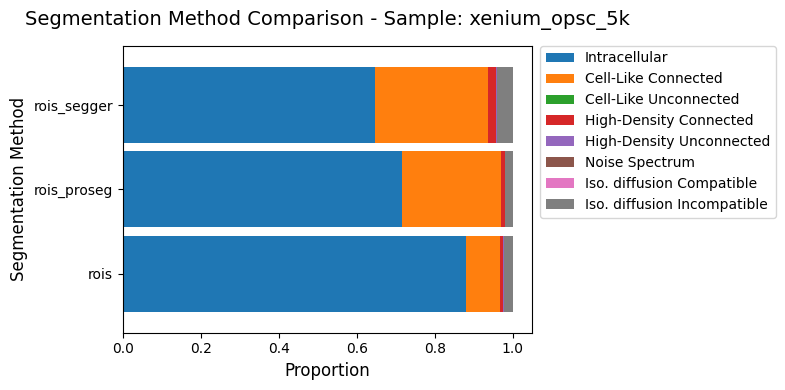

Generating segmentation comparison plot for sample: xenium_opsc_v1


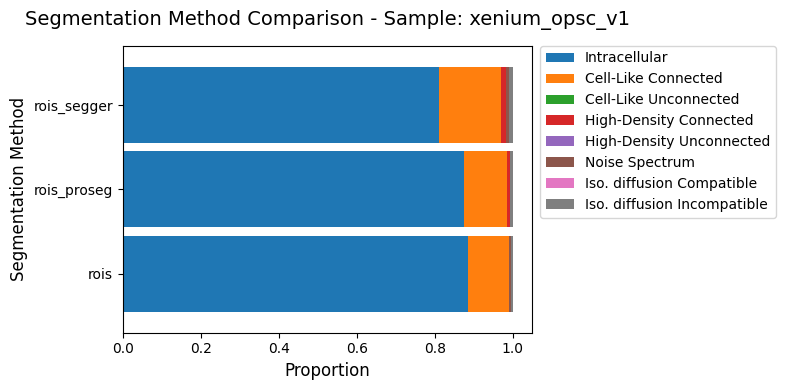

In [4]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# Ensure the saving directory exists
os.makedirs(saving_path, exist_ok=True)

# 1. Combine all segmentations into a single DataFrame with a MultiIndex (Segmentation, Sample)
all_data = pd.concat(combined_segmentations_dict, names=["Segmentation", "Sample"])

# 2. Swap the index levels so 'Sample' is the primary level, then sort
all_data = all_data.swaplevel("Segmentation", "Sample").sort_index()

# 3. Get a unique list of all samples across your datasets
unique_samples = all_data.index.get_level_values("Sample").unique()

# 4. Loop through each sample and generate its specific plot
for sample in unique_samples:
    print(f"Generating segmentation comparison plot for sample: {sample}")
    
    # Extract data just for this sample (rows will now be the segmentation methods)
    sample_df = all_data.loc[sample]
    
    # Normalize the counts to proportions for this sample (rows sum to 1)
    sample_df_norm = sample_df.div(sample_df.sum(axis=1), axis=0)
    
    # Setup the figure and axis
    fig, ax = plt.subplots(figsize=(8, 4))
    
    # Plot the different segmentation methods stacked
    # (Optional: Sort by "Intracellular" if you want a consistent baseline ordering)
    sample_df_norm.sort_values(by="Intracellular", ascending=False).plot(
        kind="barh", stacked=True, width=0.9, ax=ax
    )
    
    # 5. Clean up formatting and push the legend outside
    plt.title(f"Segmentation Method Comparison - Sample: {sample}", fontsize=14, pad=15)
    plt.xlabel("Proportion", fontsize=12)
    plt.ylabel("Segmentation Method", fontsize=12)
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
    plt.tight_layout()
    
    # 6. Save the figure uniquely using the sample/dataset name
    # Cleaning the sample name slightly in case it contains characters unsafe for filenames
    safe_sample_name = str(sample).replace("/", "_")
    plot_out_path = os.path.join(saving_path, f"sample_{safe_sample_name}_segmentation_comparison.png")
    plt.savefig(plot_out_path, dpi=300, bbox_inches="tight")
    
    # 7. Close the figure to free up memory
    plt.show(fig)

## Plot summary

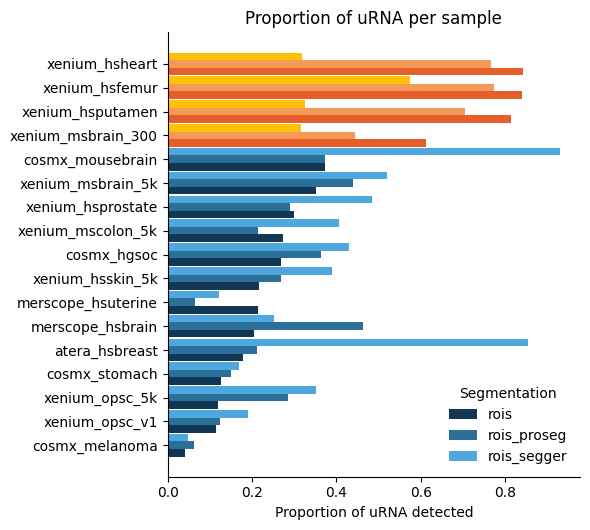

Saved custom colored uRNA comparison plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/figures/stacked_barplot_proportions_segmented.pdf


In [5]:
import os
import matplotlib.pyplot as plt
import pandas as pd

# Ensure the saving directory exists
os.makedirs(saving_path, exist_ok=True)

# 1. Combine all data into a MultiIndex DataFrame (Segmentation, Sample)
all_data = pd.concat(combined_segmentations_dict, names=["Segmentation", "Sample"])

# 2. Normalize the data to calculate proportions (rows sum to 1)
all_data_norm = all_data.div(all_data.sum(axis=1), axis=0)

# 3. Extract the Intracellular metric and reset index for pivoting
metric_df = all_data_norm[["Intracellular"]].reset_index()

# 4. Pivot the data so Samples are rows and Segmentations are columns
plot_df = metric_df.pivot(
    index="Sample", columns="Segmentation", values="Intracellular"
)

# 5. Calculate uRNA Proportion (the reverse of Intracellular)
plot_df = 1 - plot_df

# Optional: Sort the datasets for a clean visual flow
plot_df = plot_df.sort_values(by=plot_df.columns[0], ascending=True)

# 6. Define specific color palettes based on dataset type (Nuclei vs. Standard)
# These lists match the order of your columns/segmentation types dynamically
nuclei_datasets = [
    "xenium_msbrain_300",
    "xenium_hsputamen",
    "xenium_hsfemur",
    "xenium_hsheart",
]

# Base colors for Standard datasets (e.g., shades of blue/teal)
standard_colors = ["#123755", "#2A6F97", "#4EA8DE"]
# High-contrast colors for Nuclei-default datasets (e.g., warm coral/orange tones)
nuclei_colors = ["#E65F2B", "#F39A59",  "#FFC107"]

# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

# 7. Generate the plot axis
fig, ax = plt.subplots(figsize=(6, len(plot_df) * 0.2 + 2))

# 8. Plot each sample row individually to accurately control its unique color set
# This ensures grouped bars shift colors specifically for your chosen nuclei datasets
width = 0.95
n_bars = len(plot_df.columns)
bar_height = width / n_bars
y_positions = range(len(plot_df))

for idx, (sample_name, row) in enumerate(plot_df.iterrows()):
    # Determine the color palette to use for this dataset row
    is_nuclei = any(nd in sample_name for nd in nuclei_datasets)
    colors = nuclei_colors if is_nuclei else standard_colors

    # Plot each segmentation bar side-by-side inside the sample group
    for i, seg_col in enumerate(plot_df.columns):
        # Center the grouped bars vertically over the y-tick position
        y_pos = idx - (width / 2) + (i * bar_height) + (bar_height / 2)
        ax.barh(
            y_pos,
            row[seg_col],
            height=bar_height,
            color=colors[i % len(colors)],
            edgecolor="none",
            label=seg_col if idx == 0 else "",  # Avoid duplicate legends
        )

# 9. Apply your exact clean styling preferences
ax.set_yticks(y_positions)
ax.set_yticklabels(plot_df.index)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Clean legend placement without a border frame
ax.legend(loc="best", frameon=False, title="Segmentation")

plt.xlabel("Proportion of uRNA detected")
plt.ylabel("")
plt.title("Proportion of uRNA per sample")
plt.tight_layout()

# 10. Save the final vector graphic output
output_file = os.path.join(
    saving_path, "stacked_barplot_proportions_segmented.pdf"
)
plt.savefig(output_file, bbox_inches="tight")
plt.show()

print(f"Saved custom colored uRNA comparison plot to: {output_file}")

In [6]:
counts_keys = ["Intracellular", "Cell-Like Connected",
     "Cell-Like Unconnected", "High-Density Connected",
    "High-Density Unconnected", "Noise Spectrum",
    "Iso. diffusion Compatible", "Iso. diffusion Incompatible"]

combined_summary.columns=counts_keys

In [7]:
combined_summary=combined_summary.div(combined_summary.sum(axis=1),axis=0)

<Axes: >

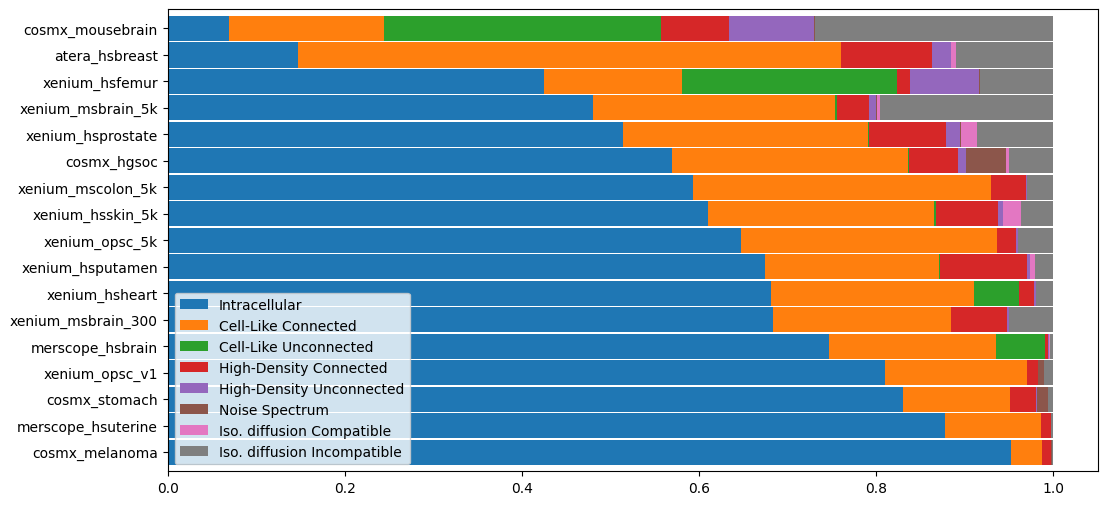

In [8]:
combined_summary.sort_values(by="Intracellular", ascending=False).plot(
    kind="barh", stacked=True, figsize=(12, 6), width=0.95
)

## Plots to define cell characteristics

In [9]:
# Load per-sample pipeline_stats.csv for each segmentation method
# (unlike transcript_categories.csv, pipeline_stats.csv is available for all 3 methods)
pipeline_stats_dict = {}

for seg in segmentations:
    root_dir = os.path.join(base_dir, seg)
    stats_list = []

    for subfolder in sorted(f.path for f in os.scandir(root_dir) if f.is_dir()):
        sample = os.path.basename(subfolder)
        if sample in excluded_samples:
            continue

        stats_path = os.path.join(subfolder, "figures/pipeline_stats.csv")

        if os.path.isfile(stats_path):
            sample_stats = pd.read_csv(stats_path, index_col="Metric")["Value"]
            sample_stats.name = sample
            stats_list.append(sample_stats)

    if stats_list:
        pipeline_stats_dict[seg] = pd.concat(stats_list, axis=1).T
        print(f"Loaded pipeline_stats for '{seg}': {pipeline_stats_dict[seg].shape}")
    else:
        print(f"No pipeline_stats.csv found for segmentation '{seg}'.")

Loaded pipeline_stats for 'rois': (17, 4)


Loaded pipeline_stats for 'rois_proseg': (17, 4)


Loaded pipeline_stats for 'rois_segger': (17, 4)


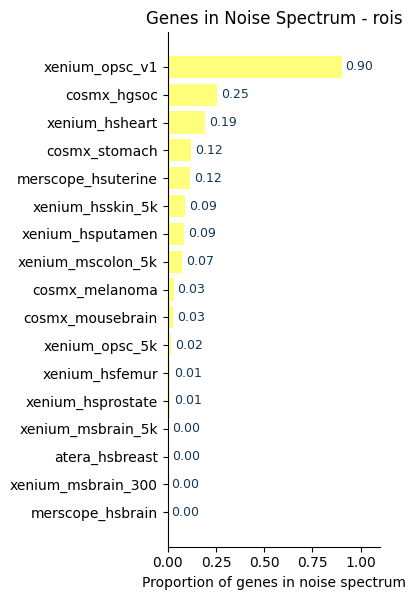

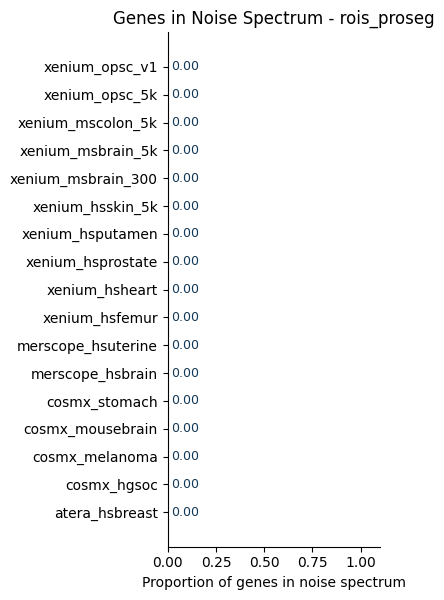

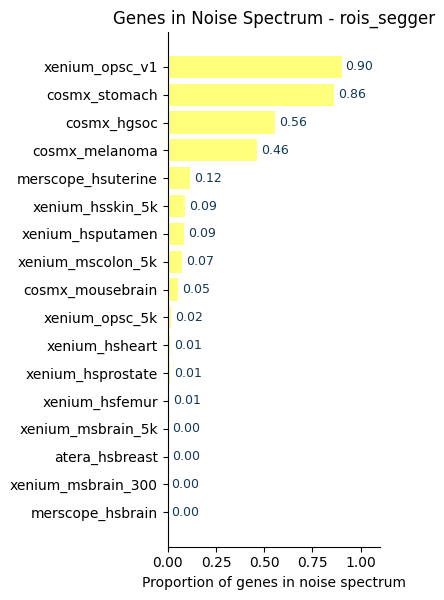

In [10]:
# Set font type for vector output
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

noise_color = troutpy.pl.get_palette("30colors")[5]  # matches "Noise Spectrum" color used above

def plot_noise_proportion(noise_values, xlabel, title, out_path):
    noise_values = noise_values.sort_values()

    fig, ax = plt.subplots(figsize=(4, 0.3 * len(noise_values) + 1))
    bars = ax.barh(noise_values.index, noise_values, color=noise_color)

    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + 0.02, bar.get_y() + bar.get_height() / 2,
            f"{width:.2f}", va="center", ha="left", color="#123755", fontsize=9,
        )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xlim(0, 1.1)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    plt.tight_layout()
    plt.savefig(out_path, bbox_inches="tight")
    plt.show()

# 1) Proportion of genes belonging to the noise spectrum, one plot per segmentation method
for seg, stats_df in pipeline_stats_dict.items():
    genes_in_noise = 1 - stats_df["genes_prop_over_noise"]
    plot_noise_proportion(
        genes_in_noise,
        xlabel="Proportion of genes in noise spectrum",
        title=f"Genes in Noise Spectrum - {seg}",
        out_path=os.path.join(saving_path, f"{seg}_barplot_genes_noise_proportion.pdf"),
    )

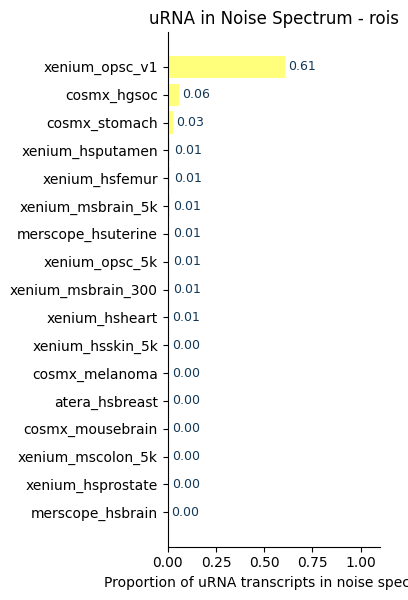

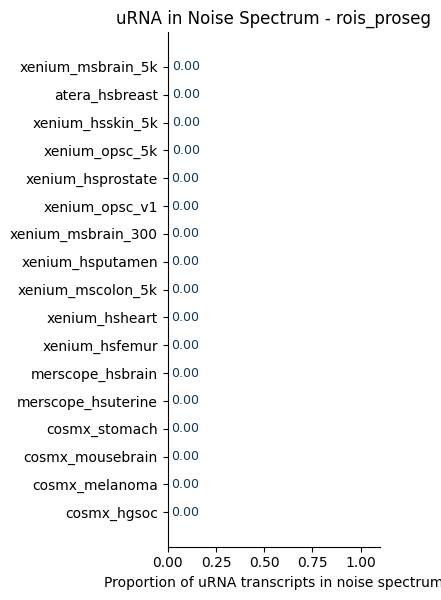

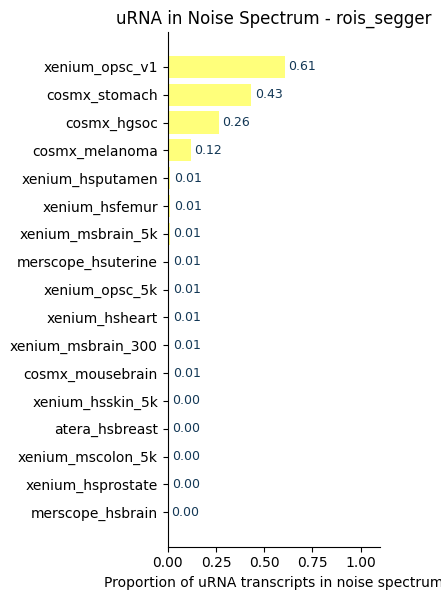

In [11]:
# 2) Proportion of uRNA transcripts assignable to the noise spectrum, one plot per segmentation method
for seg, stats_df in pipeline_stats_dict.items():
    transcripts_in_noise = 1 - stats_df["noise_RNA_proportion"]
    plot_noise_proportion(
        transcripts_in_noise,
        xlabel="Proportion of uRNA transcripts in noise spectrum",
        title=f"uRNA in Noise Spectrum - {seg}",
        out_path=os.path.join(saving_path, f"{seg}_barplot_transcripts_noise_proportion.pdf"),
    )

## uRNA proportion summary statistics (multimodal vs. nuclei-default segmentation)

In [12]:
# Compute mean/median/max/min/std of the uRNA proportion (1 - Intracellular) per sample,
# split by dataset group (multimodal-default vs. nuclei-default segmentation input)
# and reported separately for each of the three segmentation methods (def, proseg, segger).

seg_name_map = {"rois": "def", "rois_proseg": "proseg", "rois_segger": "segger"}

records = []
for seg, combined_summary in combined_segmentations_dict.items():
    seg_label = seg_name_map.get(seg, seg)

    norm = combined_summary.div(combined_summary.sum(axis=1), axis=0)
    urna_prop = 1 - norm["Intracellular"]

    is_nuclei = urna_prop.index.to_series().apply(
        lambda s: any(nd in s for nd in nuclei_datasets)
    )

    for group_name, group_urna in [
        ("multimodal", urna_prop[~is_nuclei]),
        ("nuclei", urna_prop[is_nuclei]),
    ]:
        records.append({
            "segmentation": seg_label,
            "dataset_group": group_name,
            "n_samples": len(group_urna),
            "mean": group_urna.mean(),
            "median": group_urna.median(),
            "max": group_urna.max(),
            "min": group_urna.min(),
            "std": group_urna.std(),
        })

urna_summary_stats = pd.DataFrame(records)
urna_summary_stats = urna_summary_stats.sort_values(["segmentation", "dataset_group"]).reset_index(drop=True)

csv_out_path = os.path.join(saving_path, "urna_proportion_summary_stats.csv")
urna_summary_stats.to_csv(csv_out_path, index=False)
print(f"Saved uRNA proportion summary statistics to: {csv_out_path}")

urna_summary_stats

Saved uRNA proportion summary statistics to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/figures/urna_proportion_summary_stats.csv


,segmentation,dataset_group,n_samples,mean,median,max,min,std
0,def,multimodal,13,0.213885,0.213725,0.373028,0.042031,0.097976
1,def,nuclei,4,0.777113,0.826814,0.841930,0.612895,0.110187
2,proseg,multimodal,13,0.254565,0.267595,0.463776,0.062618,0.132642
3,proseg,nuclei,4,0.672704,0.736040,0.774479,0.444255,0.155465
4,segger,multimodal,13,0.396421,0.390204,0.931197,0.048067,0.263328
5,segger,nuclei,4,0.384325,0.322531,0.575183,0.317057,0.127296
